# Этап 1. Загрузка топологической карты

Класс `TopoMapData` загружает граф локаций и локальные карты занятости.

- `graph.json` содержит вершины с `pose_for_visualization` и `edges`; поддерживается также вариант, когда рёбра хранятся в корневом ключе `edges`;
- `<node_id>/metadata.yaml` содержит параметр `resolution`;
- `<node_id>/occupancy.png` содержит карту занятости.

Целевые значения сетки: `0` — неизвестно, `1` — свободно, `2` — занято.


In [19]:
import json
from pathlib import Path

import numpy as np

try:
    import yaml
except ImportError:
    yaml = None

try:
    import cv2
except ImportError:
    cv2 = None

try:
    from PIL import Image
except ImportError:
    Image = None


def pose_to_matrix(x, y, theta):
    c = np.cos(theta)
    s = np.sin(theta)
    return np.array(
        [
            [c, -s, x],
            [s, c, y],
            [0.0, 0.0, 1.0],
        ],
        dtype=float,
    )


In [20]:
class TopoMapData:
    def __init__(self, base_path):
        self.base_path = Path(base_path).expanduser().resolve()
        self.graph_path = self.base_path / "graph.json"
        self.vertices = {}
        self.adjacency = {}
        self._map_cache = {}

    def load_graph(self):
        if not self.graph_path.exists():
            raise FileNotFoundError(f"graph.json не найден: {self.graph_path}")

        with self.graph_path.open("r", encoding="utf-8") as file:
            graph = json.load(file)

        raw_vertices = graph.get("vertices", {})
        if isinstance(raw_vertices, dict):
            vertex_items = sorted(
                (int(key), value) for key, value in raw_vertices.items()
            )
        else:
            vertex_items = list(enumerate(raw_vertices))

        root_edges = graph.get("edges")
        self.vertices = {}
        self.adjacency = {}

        for node_id, raw_vertex in vertex_items:
            pose = np.asarray(
                raw_vertex.get("pose_for_visualization", [0.0, 0.0, 0.0]),
                dtype=float,
            ).reshape(-1)
            pose = self._normalize_pose(pose)

            raw_edges = raw_vertex.get("edges")
            if raw_edges is None and root_edges is not None:
                raw_edges = self._get_root_edges(root_edges, node_id)

            edges = self._parse_edges(raw_edges)
            self.vertices[node_id] = {"pose": pose, "edges": edges}
            self.adjacency[node_id] = [edge["to"] for edge in edges]

        return self.vertices

    def load_local_map(self, node_id):
        node_id = int(node_id)
        if node_id in self._map_cache:
            resolution, grid = self._map_cache[node_id]
            return resolution, grid.copy()

        node_dir = self.base_path / str(node_id)
        metadata_path = node_dir / "metadata.yaml"
        occupancy_path = node_dir / "occupancy.png"

        if not node_dir.is_dir():
            raise FileNotFoundError(f"Папка локации не найдена: {node_dir}")
        if not occupancy_path.exists():
            raise FileNotFoundError(f"occupancy.png не найден: {occupancy_path}")

        metadata = self._load_metadata(metadata_path)
        resolution = float(metadata.get("resolution", 0.1))
        image = self._read_occupancy_image(occupancy_path)
        grid = self._to_occupancy_grid(image)

        self._map_cache[node_id] = (resolution, grid.copy())
        return resolution, grid

    def get_pose_matrix(self, node_id):
        pose = self.vertices[int(node_id)]["pose"]
        return pose_to_matrix(pose[0], pose[1], pose[2])

    def _get_root_edges(self, root_edges, node_id):
        if isinstance(root_edges, dict):
            return root_edges.get(str(node_id), root_edges.get(node_id, []))
        if isinstance(root_edges, (list, tuple)) and node_id < len(root_edges):
            candidate = root_edges[node_id]
            if isinstance(candidate, dict):
                return [candidate] if "to" in candidate else candidate
            if isinstance(candidate, (list, tuple)):
                if not candidate:
                    return []
                first = candidate[0]
                if np.isscalar(first) and len(candidate) >= 2:
                    return [
                        edge
                        for edge in root_edges
                        if isinstance(edge, (list, tuple))
                        and len(edge) >= 2
                        and int(edge[0]) == node_id
                    ]
                return candidate
        return []

    def _normalize_pose(self, pose):
        if pose.size == 2:
            return np.array([pose[0], pose[1], 0.0], dtype=float)
        if pose.size < 3:
            padded = np.zeros(3, dtype=float)
            padded[: pose.size] = pose
            return padded
        return pose[:3].astype(float, copy=True)

    def _parse_edges(self, raw_edges):
        if raw_edges is None:
            return []

        if isinstance(raw_edges, dict) and "to" in raw_edges:
            candidates = [raw_edges]
        elif isinstance(raw_edges, dict):
            candidates = []
            for target, value in raw_edges.items():
                if isinstance(value, dict):
                    item = dict(value)
                    item.setdefault("to", target)
                else:
                    item = {"to": target, "pose": value}
                candidates.append(item)
        elif isinstance(raw_edges, (list, tuple)):
            candidates = list(raw_edges)
        else:
            return []

        edges = []
        for candidate in candidates:
            edge = self._parse_edge(candidate)
            if edge is not None:
                edges.append(edge)
        return edges

    def _parse_edge(self, candidate):
        if isinstance(candidate, dict):
            if "to" not in candidate:
                return None
            target = int(candidate["to"])
            pose = candidate.get("pose")
        elif isinstance(candidate, (list, tuple)):
            if len(candidate) >= 4 and np.isscalar(candidate[0]):
                target = int(candidate[0])
                pose = candidate[1:4]
            elif len(candidate) >= 2:
                target = int(candidate[0])
                pose = candidate[1]
                if isinstance(pose, dict):
                    pose = pose.get("pose")
            else:
                return None
        else:
            return None

        pose_array = np.asarray(
            pose if pose is not None else [0.0, 0.0, 0.0],
            dtype=float,
        ).reshape(-1)
        return {"to": target, "pose": self._normalize_pose(pose_array)}

    def _load_metadata(self, metadata_path):
        if not metadata_path.exists():
            return {}
        text = metadata_path.read_text(encoding="utf-8")
        if yaml is not None:
            try:
                loaded = yaml.safe_load(text)
                if isinstance(loaded, dict):
                    return loaded
            except Exception:
                pass
        return self._parse_simple_yaml(text)

    def _parse_simple_yaml(self, text):
        result = {}
        for raw_line in text.splitlines():
            line = raw_line.strip()
            if not line or line.startswith("#") or ":" not in line:
                continue
            key, value = line.split(":", 1)
            key = key.strip()
            value = value.strip()
            if not key or not value:
                continue
            if value.lower() in {"true", "false"}:
                result[key] = value.lower() == "true"
                continue
            try:
                result[key] = float(value)
            except ValueError:
                result[key] = value.strip("'\"")
        return result

    def _read_occupancy_image(self, image_path):
        if cv2 is not None:
            image = cv2.imread(str(image_path), cv2.IMREAD_UNCHANGED)
            if image is None:
                raise ValueError(f"Не удалось прочитать изображение: {image_path}")
            if image.ndim == 3 and image.shape[2] == 3:
                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            elif image.ndim == 3 and image.shape[2] == 4:
                image = cv2.cvtColor(image, cv2.COLOR_BGRA2RGBA)
            return image

        if Image is None:
            raise ImportError("Установите opencv-python или Pillow")

        with Image.open(image_path) as image:
            if image.mode == "P":
                image = image.convert("RGBA")
            return np.array(image)

    def _to_occupancy_grid(self, image):
        array = np.asarray(image)
        alpha = None

        if array.ndim == 3:
            if array.shape[2] == 4:
                alpha = array[..., 3]
            rgb = array[..., :3].astype(float)
            gray = (
                rgb[..., 0] * 0.299
                + rgb[..., 1] * 0.587
                + rgb[..., 2] * 0.114
            )
        else:
            gray = array.astype(float)

        if array.dtype == bool:
            gray = gray * 255.0

        max_value = float(np.nanmax(gray)) if gray.size else 0.0
        if np.issubdtype(array.dtype, np.floating) and max_value <= 1.0:
            gray = gray * 255.0
        elif max_value > 255.0:
            gray = gray / max(max_value, 1.0) * 255.0

        gray = np.clip(np.rint(gray), 0, 255).astype(np.uint8)
        unique_values = np.unique(gray)

        if unique_values.size > 0 and int(unique_values.max()) <= 2:
            grid = gray.astype(np.uint8)
        else:
            grid = np.zeros(gray.shape, dtype=np.uint8)
            grid[gray >= 220] = 1
            grid[gray <= 40] = 2

        if alpha is not None:
            grid[np.asarray(alpha) == 0] = 0

        return grid


In [21]:
from pathlib import Path

data_root = Path("2n8kARJN3HM")
if not (data_root / "graph.json").exists():
    candidates = sorted(Path(".").glob("*/graph.json"))
    if candidates:
        data_root = candidates[0].parent

topo_map = TopoMapData(data_root)
vertices = topo_map.load_graph()

print(f"Корневая папка: {topo_map.base_path}")
print(f"Вершин: {len(vertices)}")
print(f"Рёбер: {sum(len(vertex['edges']) for vertex in vertices.values())}")
print(f"Первые вершины: {list(vertices)[:5]}")


Корневая папка: /home/dmitry/explorer_view/2n8kARJN3HM
Вершин: 95
Рёбер: 252
Первые вершины: [0, 1, 2, 3, 4]


In [22]:
first_node = next(iter(vertices))

print(f"Вершина: {first_node}")
print(f"Поза: {vertices[first_node]['pose']}")
print(f"Исходящие рёбра: {vertices[first_node]['edges'][:2]}")
print("Матрица однородного преобразования:")
print(topo_map.get_pose_matrix(first_node))

resolution, grid = topo_map.load_local_map(first_node)
values, counts = np.unique(grid, return_counts=True)

print(f"resolution: {resolution}")
print(f"shape: {grid.shape}, dtype: {grid.dtype}")
print(f"значения сетки: {dict(zip(values.tolist(), counts.tolist()))}")


Вершина: 0
Поза: [-0.4175728  -2.68826921 -1.09942506]
Исходящие рёбра: [{'to': 1, 'pose': array([ 3.87751452, -3.37161212, -1.11701083])}]
Матрица однородного преобразования:
[[ 0.45410844  0.89094642 -0.4175728 ]
 [-0.89094642  0.45410844 -2.68826921]
 [ 0.          0.          1.        ]]
resolution: 0.1
shape: (360, 360), dtype: uint8
значения сетки: {0: 121250, 1: 7560, 2: 790}


In [23]:
loaded = {}

for node_id in vertices:
    resolution, grid = topo_map.load_local_map(node_id)
    loaded[node_id] = (resolution, grid.shape)

print(f"Загружено локальных карт: {len(loaded)}")
print(f"Уникальные resolution: {sorted({item[0] for item in loaded.values()})}")
print(f"Уникальные размеры: {sorted({item[1] for item in loaded.values()})}")


Загружено локальных карт: 95
Уникальные resolution: [0.1]
Уникальные размеры: [(360, 360)]



Все локальные карты занятости вставляются в единую глобальную сетку по `pose_for_visualization`. Слияние выполняется поэлементной максимизацией: если хотя бы на одной карте клетка занята (`2`), в объединении она тоже занята. Локальная карта переводится в глобальные пиксели аффинным преобразованием (сдвиг центра → поворот на `theta` → сдвиг в глобальную сетку) с учётом инверсии оси Y.

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap


def stitch_global_map(topo_map):
    resolution = None
    min_x = min_y = np.inf
    max_x = max_y = -np.inf
    for node_id in topo_map.vertices:
        x, y, _ = topo_map.vertices[node_id]["pose"]
        min_x = min(min_x, x)
        max_x = max(max_x, x)
        min_y = min(min_y, y)
        max_y = max(max_y, y)
        res, _ = topo_map.load_local_map(node_id)
        if resolution is None:
            resolution = res

    padding = 20.0
    world_min_x = min_x - padding
    world_max_x = max_x + padding
    world_min_y = min_y - padding
    world_max_y = max_y + padding

    width = int(np.ceil((world_max_x - world_min_x) / resolution))
    height = int(np.ceil((world_max_y - world_min_y) / resolution))
    global_grid = np.zeros((height, width), dtype=np.uint8)

    for node_id in topo_map.vertices:
        res, local_grid = topo_map.load_local_map(node_id)
        x, y, theta = topo_map.vertices[node_id]["pose"]
        h_loc, w_loc = local_grid.shape
        cx, cy = w_loc / 2.0, h_loc / 2.0
        c, s = np.cos(theta), np.sin(theta)
        tx = -c * cx - s * cy + (x - world_min_x) / res
        ty = s * cx - c * cy + (world_max_y - y) / res
        matrix = np.array([[c, s, tx], [-s, c, ty]], dtype=np.float32)
        warped = cv2.warpAffine(
            local_grid,
            matrix,
            (width, height),
            flags=cv2.INTER_NEAREST,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0,
        )
        global_grid = np.maximum(global_grid, warped)

    params = {
        "resolution": resolution,
        "min_x": float(min_x),
        "max_x": float(max_x),
        "min_y": float(min_y),
        "max_y": float(max_y),
        "world_min_x": float(world_min_x),
        "world_max_x": float(world_max_x),
        "world_min_y": float(world_min_y),
        "world_max_y": float(world_max_y),
        "width": width,
        "height": height,
        "padding": padding,
    }
    return global_grid, params


def world_to_global_pixel(x, y, params):
    col = (x - params["world_min_x"]) / params["resolution"]
    row = (params["world_max_y"] - y) / params["resolution"]
    return row, col

Размер глобальной сетки: (599, 606)
Разрешение, м/пиксель: 0.1
Bounding box поз: x = [-6.94, 13.63], y = [-16.42, 3.39]
Значения сетки: {0: 226604, 1: 95746, 2: 40644}


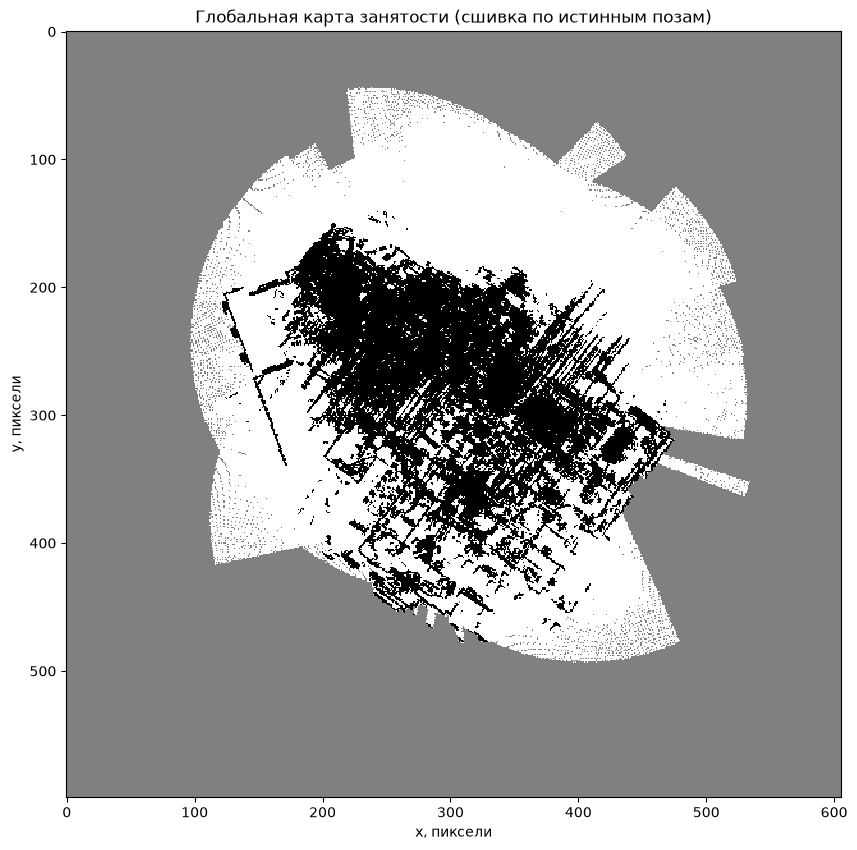

In [25]:
global_grid, global_params = stitch_global_map(topo_map)

print("Размер глобальной сетки:", global_grid.shape)
print("Разрешение, м/пиксель:", global_params["resolution"])
print(
    "Bounding box поз: x = [%.2f, %.2f], y = [%.2f, %.2f]"
    % (
        global_params["min_x"],
        global_params["max_x"],
        global_params["min_y"],
        global_params["max_y"],
    )
)
values, counts = np.unique(global_grid, return_counts=True)
print("Значения сетки:", {int(v): int(c) for v, c in zip(values, counts)})

occupancy_cmap = ListedColormap(["gray", "white", "black"])
occupancy_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], occupancy_cmap.N)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(
    global_grid,
    cmap=occupancy_cmap,
    norm=occupancy_norm,
    interpolation="nearest",
)
ax.set_title("Глобальная карта занятости (сшивка по истинным позам)")
ax.set_xlabel("x, пиксели")
ax.set_ylabel("y, пиксели")
plt.show()

## Локальная сшивка пар карт и раздутие препятствий

Для каждого ребра графа карта соседа (`node_to`) накладывается на карту текущей локации (`node_from`) по локальному сдвигу `(x, y, theta)` из `graph.json`, после чего выполняется поэлементная максимизация и раздутие препятствий на `r = 0.25` м. Раздутие реализовано эллиптическим структурным элементом `cv2.dilate`.

In [26]:
import math
import cv2
import numpy as np


def inflate_obstacles(grid, radius_m=0.25, resolution=0.1):
    r_pix = math.ceil(radius_m / resolution)
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (2 * r_pix + 1, 2 * r_pix + 1)
    )
    obstacles = (grid == 2).astype(np.uint8)
    inflated = cv2.dilate(obstacles, kernel)
    new_grid = grid.copy()
    new_grid[inflated == 1] = 2
    return new_grid


def stitch_local_pair(topo_map, node_from, edge):
    node_to = int(edge["to"])
    res_from, grid_from = topo_map.load_local_map(node_from)
    res_to, grid_to = topo_map.load_local_map(node_to)
    h, w = grid_from.shape
    h_to, w_to = grid_to.shape
    cx, cy = w / 2.0, h / 2.0
    cx_to, cy_to = w_to / 2.0, h_to / 2.0
    x, y, theta = edge["pose"]
    c, s = math.cos(theta), math.sin(theta)
    tx = cx + x / res_from - c * cx_to - s * cy_to
    ty = cy - y / res_from + s * cx_to - c * cy_to
    matrix = np.array([[c, s, tx], [-s, c, ty]], dtype=np.float32)
    warped = cv2.warpAffine(
        grid_to,
        matrix,
        (w, h),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0,
    )
    merged = np.maximum(grid_from, warped)
    return inflate_obstacles(merged, radius_m=0.25, resolution=res_from)

In [27]:
local_stitched_maps = {}
for node_from, vertex in topo_map.vertices.items():
    for edge in vertex["edges"]:
        node_to = int(edge["to"])
        local_stitched_maps[(node_from, node_to)] = stitch_local_pair(
            topo_map, node_from, edge
        )

print("Локально сшитых карт:", len(local_stitched_maps))
print(
    "Уникальных неориентированных рёбер:",
    len({tuple(sorted(key)) for key in local_stitched_maps}),
)

Локально сшитых карт: 252
Уникальных неориентированных рёбер: 126


Выбранные рёбра: [(81, 82), (33, 11), (73, 30)]


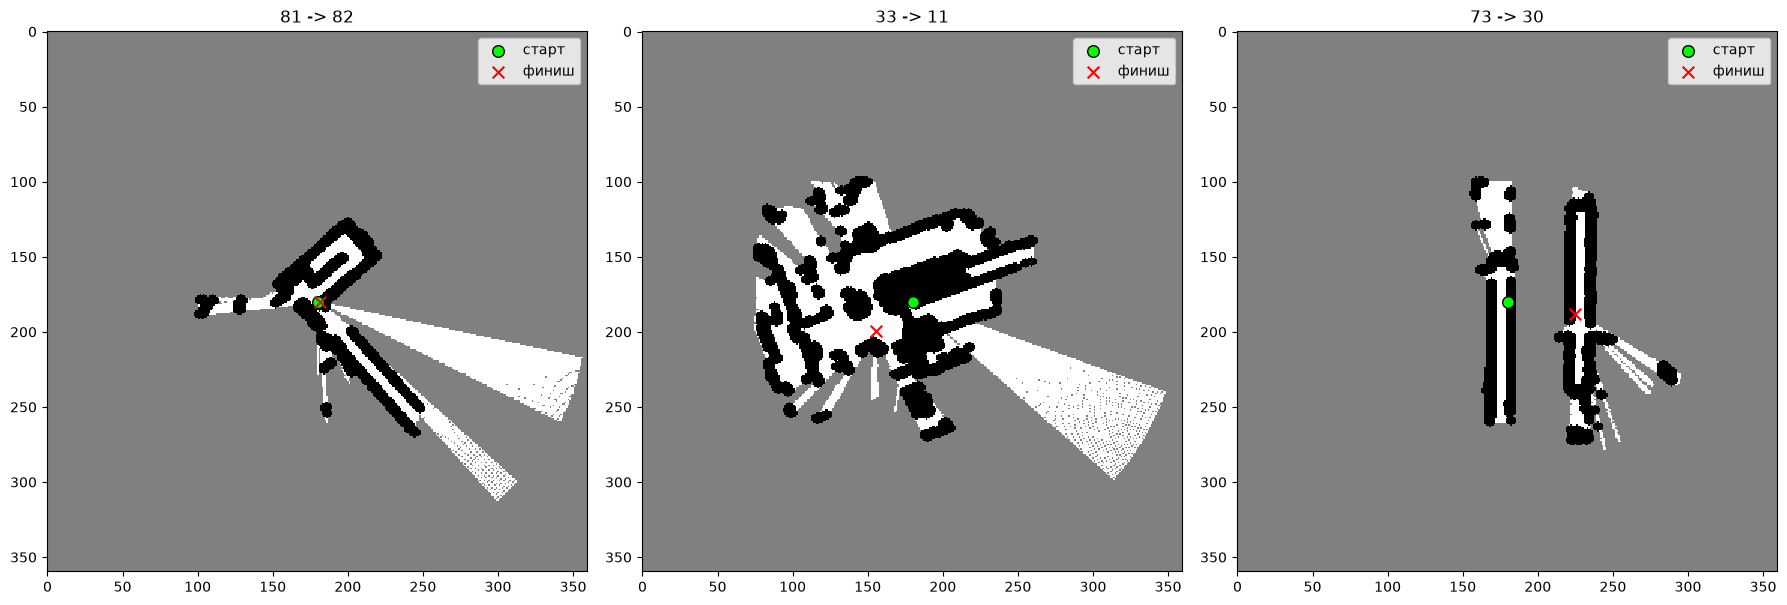

In [28]:
import random

random.seed(0)
sample_keys = random.sample(list(local_stitched_maps), 3)
print("Выбранные рёбра:", sample_keys)

fig, axes = plt.subplots(1, len(sample_keys), figsize=(6 * len(sample_keys), 6))
if len(sample_keys) == 1:
    axes = [axes]

for ax, key in zip(axes, sample_keys):
    node_from, node_to = key
    grid = local_stitched_maps[key]
    edge = next(
        e for e in topo_map.vertices[node_from]["edges"] if int(e["to"]) == node_to
    )
    x, y, _ = edge["pose"]
    res, _ = topo_map.load_local_map(node_from)
    h, w = grid.shape
    start_row, start_col = h / 2.0, w / 2.0
    goal_row = start_row - y / res
    goal_col = start_col + x / res

    ax.imshow(
        grid,
        cmap=occupancy_cmap,
        norm=occupancy_norm,
        interpolation="nearest",
    )
    ax.scatter(
        [start_col],
        [start_row],
        c="lime",
        s=70,
        marker="o",
        edgecolors="black",
        label="старт",
    )
    ax.scatter([goal_col], [goal_row], c="red", s=70, marker="x", label="финиш")
    ax.set_title(f"{node_from} -> {node_to}")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()